# Superstore Sales: Business Intelligence Assignment
**Topics:** OLTP simulation, OLAP-style aggregation, descriptive analytics, dashboard visualization, and ethics


## Step 0. Setup

In [ ]:
!pip -q install python-docx openpyxl

import os, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from matplotlib.gridspec import GridSpec

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 5.8 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Step 1. Import the dataset

In [3]:
FILE_NAME = "/content/drive/MyDrive/cf_superstore_sales_dataset.xlsx"

if not os.path.exists(FILE_NAME):
    try:
        from google.colab import files
        uploaded = files.upload()
        FILE_NAME = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Place {FILE_NAME} in the working folder.")

df_raw = pd.read_excel(FILE_NAME)
df = df_raw.copy()
print(f"Loaded '{FILE_NAME}': {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Saving cf_superstore_sales_dataset.xlsx to cf_superstore_sales_dataset.xlsx
Loaded 'cf_superstore_sales_dataset.xlsx': 9,994 rows x 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2015-749146,2018-01-31,2018-02-04,Same Day,CA-15380,Michael Williams,Home Office,United States,Laredo,Utah,79907,South,PRD-29860,Furniture,Accessories,Stapler Office Quite,6.07,8,0.20,1.55
1,2,US-2016-918354,2018-12-30,2019-01-04,Standard Class,OE-15360,Paula Simpson,Consumer,United States,Davis,Nebraska,39212,East,PRD-68149,Technology,Fasteners,Deluxe Desk Especially,524.17,9,0.50,-26.98
2,3,US-2018-679217,2017-05-10,2017-05-13,Second Class,SM-24012,Taylor Roach,Consumer,United States,Perth Amboy,California,55407,West,PRD-96192,Furniture,Art,Deluxe Pro Serious,453.76,7,0.30,-24.09
3,4,CA-2017-494108,2018-07-18,2018-07-27,Same Day,OG-75256,Joseph Young,Home Office,United States,Arvada,Delaware,6360,Central,PRD-27929,Office Supplies,Storage,Series Stapler World,415.08,9,0.20,38.72
4,5,CA-2017-434878,2018-02-04,2018-02-13,Second Class,VL-13831,John Black,Home Office,United States,Parker,Alabama,43055,West,PRD-50062,Furniture,Bookcases,Stapler Desk Trial,504.33,2,0.40,-87.17


## Step 2. Explore and clean the data

### 2.1 First look

In [4]:
print("Columns:", list(df.columns))
df.info()

Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State  

In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nExact duplicate rows (all columns):", df_raw.duplicated().sum())
df.describe()

Missing values per column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Exact duplicate rows (all columns): 0


,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,"9,994.00",9994,9994,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,"4,997.50",2017-01-08 02:01:45.183109888,2017-01-13 01:50:56.794076672,"55,668.75",502.63,4.99,0.25,-0.83
min,1.00,2015-01-01 00:00:00,2015-01-03 00:00:00,"1,040.00",1.13,1.00,0.00,-466.14
25%,"2,499.25",2016-01-16 00:00:00,2016-01-22 00:00:00,"32,712.00",251.43,3.00,0.10,-68.35
50%,"4,997.50",2017-01-15 00:00:00,2017-01-21 00:00:00,"55,433.00",507.68,5.00,0.30,-0.69
75%,"7,495.75",2018-01-07 00:00:00,2018-01-12 00:00:00,"80,906.00",753.33,7.00,0.40,66.68
max,"9,994.00",2018-12-31 00:00:00,2019-01-09 00:00:00,"99,301.00",999.87,9.00,0.50,480.70
std,"2,885.16",NaN,NaN,"29,170.96",287.73,2.57,0.17,127.75


### 2.2 Cleaning

In [6]:
# Standardise column names and text
df.columns = df.columns.str.strip()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()

# Fix data types
# Dates in the file are day/month/year, so dayfirst=True is required.
for c in ["Order Date", "Ship Date"]:
    df[c] = pd.to_datetime(df[c], dayfirst=True, errors="coerce")
df["Postal Code"] = df["Postal Code"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(5)
for c in ["Sales", "Quantity", "Discount", "Profit"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Missing values: drop only rows missing a field the analysis cannot work without
key_fields = ["Order ID", "Order Date", "Sales", "Quantity"]
before = len(df)
df = df.dropna(subset=key_fields)
rows_dropped_missing = before - len(df)

# Duplicates: Row ID is unique by design, so compare every OTHER column
dup_cols = [c for c in df.columns if c != "Row ID"]
dup_count = int(df.duplicated(subset=dup_cols).sum())
df = df.drop_duplicates(subset=dup_cols)

print(f"Rows dropped (missing key fields): {rows_dropped_missing}")
print(f"Rows dropped (duplicates):         {dup_count}")
print(f"Rows remaining:                    {len(df):,}")
df.dtypes

Rows dropped (missing key fields): 0
Rows dropped (duplicates):         0
Rows remaining:                    9,994


,0
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


### 2.3 Incorrect-value checks
These checks **flag** suspicious records for review. They do not silently change the sales figures.

In [7]:
order_id_year = pd.to_numeric(df["Order ID"].str.extract(r"-(\d{4})-")[0], errors="coerce")

checks = {
    "Quantity <= 0":                         (df["Quantity"] <= 0),
    "Negative Sales":                        (df["Sales"] < 0),
    "Discount outside 0-1":                  (~df["Discount"].between(0, 1)),
    "Ship Date before Order Date":           (df["Ship Date"] < df["Order Date"]),
    "Order ID year differs from Order Date": (order_id_year != df["Order Date"].dt.year),
    "Loss-making line (Profit < 0)":         (df["Profit"] < 0),
}
quality = pd.DataFrame({"Records flagged": {k: int(v.sum()) for k, v in checks.items()}})
quality["% of rows"] = quality["Records flagged"] / len(df) * 100
quality

,Records flagged,% of rows
Quantity <= 0,0,0.00
Negative Sales,0,0.00
Discount outside 0-1,0,0.00
Ship Date before Order Date,0,0.00
Order ID year differs from Order Date,7523,75.28
Loss-making line (Profit < 0),5062,50.65


In [8]:
# Region vs State consistency: does each State map to one Region?
state_region = df.groupby("State")["Region"].nunique()
inconsistent_states = int((state_region > 1).sum())
print(f"States appearing in more than one Region: {inconsistent_states} of {len(state_region)}")

# Derived columns used later
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["YearMonth"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df = df.reset_index(drop=True)
print(f"Date range: {df['Order Date'].min():%d %b %Y} to {df['Order Date'].max():%d %b %Y}")

States appearing in more than one Region: 49 of 49
Date range: 01 Jan 2015 to 31 Dec 2018


## Step 3. Simulate OLTP
**OLTP (Online Transaction Processing)** stores and processes individual business events quickly and accurately. Here each row is one sales line item. The transaction-level fields are:

`Row ID` (primary key), `Order ID`, `Order Date`, `Customer ID`, `Product ID`, `Product Name`, `Quantity`, `Sales`, `Discount`, `Profit`.

The cells below load these fields into a small **in-memory SQLite database** (a relational, OLTP-style store), then retrieve and validate one transaction. **No sales record is created or modified.**

In [9]:
conn = sqlite3.connect(":memory:")
conn.execute("""
CREATE TABLE sales_transactions (
    Row_ID       INTEGER PRIMARY KEY,
    Order_ID     TEXT    NOT NULL,
    Order_Date   TEXT    NOT NULL,
    Customer_ID  TEXT,
    Product_ID   TEXT,
    Product_Name TEXT,
    Quantity     INTEGER NOT NULL CHECK (Quantity > 0),
    Sales        REAL    NOT NULL,
    Discount     REAL    CHECK (Discount BETWEEN 0 AND 1),
    Profit       REAL
)""")

oltp_fields = ["Row ID", "Order ID", "Order Date", "Customer ID", "Product ID",
               "Product Name", "Quantity", "Sales", "Discount", "Profit"]
tx = df[oltp_fields].copy()
tx["Order Date"] = tx["Order Date"].dt.strftime("%Y-%m-%d")
tx.columns = [c.replace(" ", "_") for c in tx.columns]
tx.to_sql("sales_transactions", conn, if_exists="append", index=False)

print("Transactions stored:", conn.execute("SELECT COUNT(*) FROM sales_transactions").fetchone()[0])

Transactions stored: 9994


### 3.1 Retrieve a single transaction (point lookup by primary key)

In [10]:
sample_row_id = int(df["Row ID"].iloc[0])
one_tx = pd.read_sql_query("SELECT * FROM sales_transactions WHERE Row_ID = ?", conn, params=(sample_row_id,))
one_tx

,Row_ID,Order_ID,Order_Date,Customer_ID,Product_ID,Product_Name,Quantity,Sales,Discount,Profit
0,1,US-2015-749146,2018-01-31,CA-15380,PRD-29860,Stapler Office Quite,8,6.07,0.20,1.55


### 3.2 Validate the transaction's fields

In [12]:
def validate_transaction(rec: dict) -> list:
    """Return a list of validation problems (empty list = valid)."""
    problems = []
    for f in ["Order_ID", "Order_Date", "Customer_ID", "Product_ID"]:
        if rec.get(f) in (None, "", "nan"):
            problems.append(f"{f} is missing")
    if pd.isna(pd.to_datetime(rec.get("Order_Date"), errors="coerce")):
        problems.append("Order_Date is not a valid date")
    if not (rec.get("Quantity") or 0) > 0:
        problems.append("Quantity must be positive")
    if (rec.get("Sales") is None) or rec["Sales"] < 0:
        problems.append("Sales must be non-negative")
    if not 0 <= (rec.get("Discount") if rec.get("Discount") is not None else 0) <= 1:
        problems.append("Discount must be between 0 and 1")
    return problems

record = one_tx.iloc[0].to_dict()
issues = validate_transaction(record)
print(f"Transaction Row ID {sample_row_id} ({record['Order_ID']}):")
print("  VALID" if not issues else f"  INVALID -> {issues}")

Transaction Row ID 1 (US-2015-749146):
  VALID


### 3.3 Retrieve all line items of one order, then validate every stored transaction

In [13]:
order_lines = pd.read_sql_query(
    "SELECT Row_ID, Order_ID, Product_Name, Quantity, Sales, Discount, Profit "
    "FROM sales_transactions WHERE Order_ID = ?", conn, params=(record["Order_ID"],))
display(order_lines)

all_tx = pd.read_sql_query("SELECT * FROM sales_transactions", conn)
all_tx["problems"] = all_tx.apply(lambda r: validate_transaction(r.to_dict()), axis=1)
valid_count = int((all_tx["problems"].str.len() == 0).sum())
print(f"Transactions passing validation: {valid_count:,} of {len(all_tx):,} ({valid_count/len(all_tx):.1%})")

,Row_ID,Order_ID,Product_Name,Quantity,Sales,Discount,Profit
0,1,US-2015-749146,Stapler Office Quite,8,6.07,0.20,1.55


Transactions passing validation: 9,994 of 9,994 (100.0%)


## Step 4. OLAP-style analysis
**OLAP (Online Analytical Processing)** summarises many transactions along dimensions (category, region, time) to answer business questions. We use `groupby()`, aggregation functions, and pivot tables.

### 4.1 Key business metrics

In [14]:
total_sales   = df["Sales"].sum()
total_profit  = df["Profit"].sum()
total_orders  = df["Order ID"].nunique()
total_lines   = len(df)
total_qty     = int(df["Quantity"].sum())
aov           = total_sales / total_orders
profit_margin = total_profit / total_sales
total_customers = df["Customer ID"].nunique()

kpis = pd.Series({
    "Total Sales": f"${total_sales:,.2f}",
    "Total Profit": f"${total_profit:,.2f}",
    "Profit Margin": f"{profit_margin:.2%}",
    "Total Orders (unique Order IDs)": f"{total_orders:,}",
    "Transaction lines recorded": f"{total_lines:,}",
    "Units sold": f"{total_qty:,}",
    "Average Order Value": f"${aov:,.2f}",
    "Unique customers": f"{total_customers:,}",
}, name="Value")
kpis.to_frame()

,Value
Total Sales,"$5,023,276.42"
Total Profit,"$-8,295.89"
Profit Margin,-0.17%
Total Orders (unique Order IDs),"9,994"
Transaction lines recorded,"9,994"
Units sold,"49,828"
Average Order Value,$502.63
Unique customers,"9,993"


### 4.2 Which category generates the most sales?

In [15]:
def summarise(by):
    out = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                             Orders=("Order ID", "nunique"), Units=("Quantity", "sum"),
                             Avg_Discount=("Discount", "mean"))
    out["Profit Margin %"] = out["Profit"] / out["Sales"] * 100
    out["Share of Sales %"] = out["Sales"] / out["Sales"].sum() * 100
    return out.sort_values("Sales", ascending=False)

by_category = summarise("Category")
by_category

,Sales,Profit,Orders,Units,Avg_Discount,Profit Margin %,Share of Sales %
Category,,,,,,,
Office Supplies,"1,694,191.27","3,394.31",3391,17031,0.25,0.20,33.73
Technology,"1,689,275.00","-13,370.54",3308,16545,0.25,-0.79,33.63
Furniture,"1,639,810.15","1,680.34",3295,16252,0.25,0.10,32.64


### 4.3 Which region performs best?

In [16]:
by_region = summarise("Region")
by_region

,Sales,Profit,Orders,Units,Avg_Discount,Profit Margin %,Share of Sales %
Region,,,,,,,
East,"1,299,695.57","-3,108.78",2574,12790,0.25,-0.24,25.87
West,"1,259,232.17","1,061.45",2506,12465,0.25,0.08,25.07
South,"1,239,127.48","-5,983.70",2503,12490,0.25,-0.48,24.67
Central,"1,225,221.20",-264.86,2411,12083,0.25,-0.02,24.39


### 4.4 How do sales change by month?

In [17]:
monthly = df.groupby("YearMonth").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                      Orders=("Order ID", "nunique"))
yearly = summarise("Year").sort_index()
display(monthly.head(12))
print("Yearly summary:")
yearly

,Sales,Profit,Orders
YearMonth,,,
2015-01-01,"107,381.20","1,786.95",211
2015-02-01,"97,898.37","-2,537.11",175
2015-03-01,"95,281.33","1,424.02",192
2015-04-01,"94,185.38","1,268.56",199
2015-05-01,"107,880.40","-3,979.16",215
2015-06-01,"103,708.92","2,703.70",199
2015-07-01,"99,562.57","-1,501.69",212
2015-08-01,"110,732.71","-1,668.74",228
2015-09-01,"100,730.40",505.90,195


Yearly summary:


,Sales,Profit,Orders,Units,Avg_Discount,Profit Margin %,Share of Sales %
Year,,,,,,,
2015,"1,198,950.07","-5,112.22",2389,11736,0.25,-0.43,23.87
2016,"1,242,186.37","-4,089.61",2521,12504,0.25,-0.33,24.73
2017,"1,282,226.33","-5,177.50",2523,12780,0.25,-0.40,25.53
2018,"1,299,913.65","6,083.44",2561,12808,0.25,0.47,25.88


In [18]:
# Seasonality: average sales for each calendar month across all years
seasonal = df.groupby("Month")["Sales"].sum()
seasonal.index = pd.to_datetime(seasonal.index, format="%m").strftime("%b")
seasonal

,Sales
Month,
Jan,"446,566.31"
Feb,"406,864.08"
Mar,"416,214.72"
Apr,"417,792.68"
May,"438,704.37"
Jun,"401,644.28"
Jul,"424,206.45"
Aug,"439,499.67"
Sep,"416,878.50"


### 4.5 Pivot tables

In [19]:
pivot_cat_region = pd.pivot_table(df, values="Sales", index="Category", columns="Region",
                                  aggfunc="sum", margins=True, margins_name="Total", fill_value=0)
display(pivot_cat_region)

pivot_profit = pd.pivot_table(df, values="Profit", index="Category", columns="Region",
                              aggfunc="sum", margins=True, margins_name="Total", fill_value=0)
display(pivot_profit)

pivot_year_month = pd.pivot_table(df, values="Sales", index="Month", columns="Year",
                                  aggfunc="sum", fill_value=0)
pivot_year_month

Region,Central,East,South,West,Total
Category,,,,,
Furniture,"378,751.83","418,589.76","417,596.94","424,871.62","1,639,810.15"
Office Supplies,"433,617.74","449,623.80","387,064.68","423,885.05","1,694,191.27"
Technology,"412,851.63","431,482.01","434,465.86","410,475.50","1,689,275.00"
Total,"1,225,221.20","1,299,695.57","1,239,127.48","1,259,232.17","5,023,276.42"


Region,Central,East,South,West,Total
Category,,,,,
Furniture,-673.99,978.99,"1,393.65",-18.31,"1,680.34"
Office Supplies,"2,618.32",712.35,"-1,061.61","1,125.25","3,394.31"
Technology,"-2,209.19","-4,800.12","-6,315.74",-45.49,"-13,370.54"
Total,-264.86,"-3,108.78","-5,983.70","1,061.45","-8,295.89"


Year,2015,2016,2017,2018
Month,,,,
1,"107,381.20","111,318.68","106,992.41","120,874.02"
2,"97,898.37","97,697.05","98,249.64","113,019.02"
3,"95,281.33","99,829.50","112,399.58","108,704.31"
4,"94,185.38","98,661.36","117,684.78","107,261.16"
5,"107,880.40","106,791.62","106,914.01","117,118.34"
6,"103,708.92","104,550.90","102,193.51","91,190.95"
7,"99,562.57","94,651.36","122,152.14","107,840.38"
8,"110,732.71","106,876.83","111,145.88","110,744.25"
9,"100,730.40","108,707.52","96,757.11","110,683.47"


### 4.6 Extra drill-downs (profit drivers)

In [20]:
by_subcat = summarise(["Category", "Sub-Category"]).sort_values("Profit")
print("Five weakest sub-categories by profit:")
display(by_subcat.head(5)[["Sales", "Profit", "Profit Margin %"]])

by_segment = summarise("Segment")
display(by_segment[["Sales", "Profit", "Profit Margin %"]])

discount_band = pd.cut(df["Discount"], bins=[-0.001, 0, 0.2, 0.4, 1.0],
                       labels=["No discount", "Up to 20%", "21-40%", "Above 40%"])
by_discount = df.groupby(discount_band).agg(Lines=("Sales", "size"), Sales=("Sales", "sum"),
                                            Profit=("Profit", "sum"))
by_discount["Profit Margin %"] = by_discount["Profit"] / by_discount["Sales"] * 100
discount_corr = df[["Discount", "Profit"]].corr().iloc[0, 1]
print(f"Correlation between Discount and Profit: {discount_corr:.3f}")
by_discount

Five weakest sub-categories by profit:


Sales    Profit  Profit Margin %
Category        Sub-Category                                      
Furniture       Supplies      91,952.28 -3,313.35            -3.60
Technology      Art           97,179.80 -3,044.03            -3.13
                Phones        96,767.16 -3,037.48            -3.14
                Labels        82,064.59 -2,943.25            -3.59
Office Supplies Binders      115,539.32 -2,666.28            -2.31

,Sales,Profit,Profit Margin %
Segment,,,
Consumer,"1,715,244.09",810.76,0.05
Home Office,"1,685,138.63","1,683.46",0.10
Corporate,"1,622,893.70","-10,790.11",-0.66


Correlation between Discount and Profit: -0.004


,Lines,Sales,Profit,Profit Margin %
Discount,,,,
No discount,1710,"846,341.71","5,191.69",0.61
Up to 20%,3283,"1,660,745.91","-6,886.50",-0.41
21-40%,3361,"1,684,507.01","-4,315.05",-0.26
Above 40%,1640,"831,681.79","-2,286.03",-0.27


## Step 5. Dashboard
KPI cards plus charts, all generated from the aggregations above.

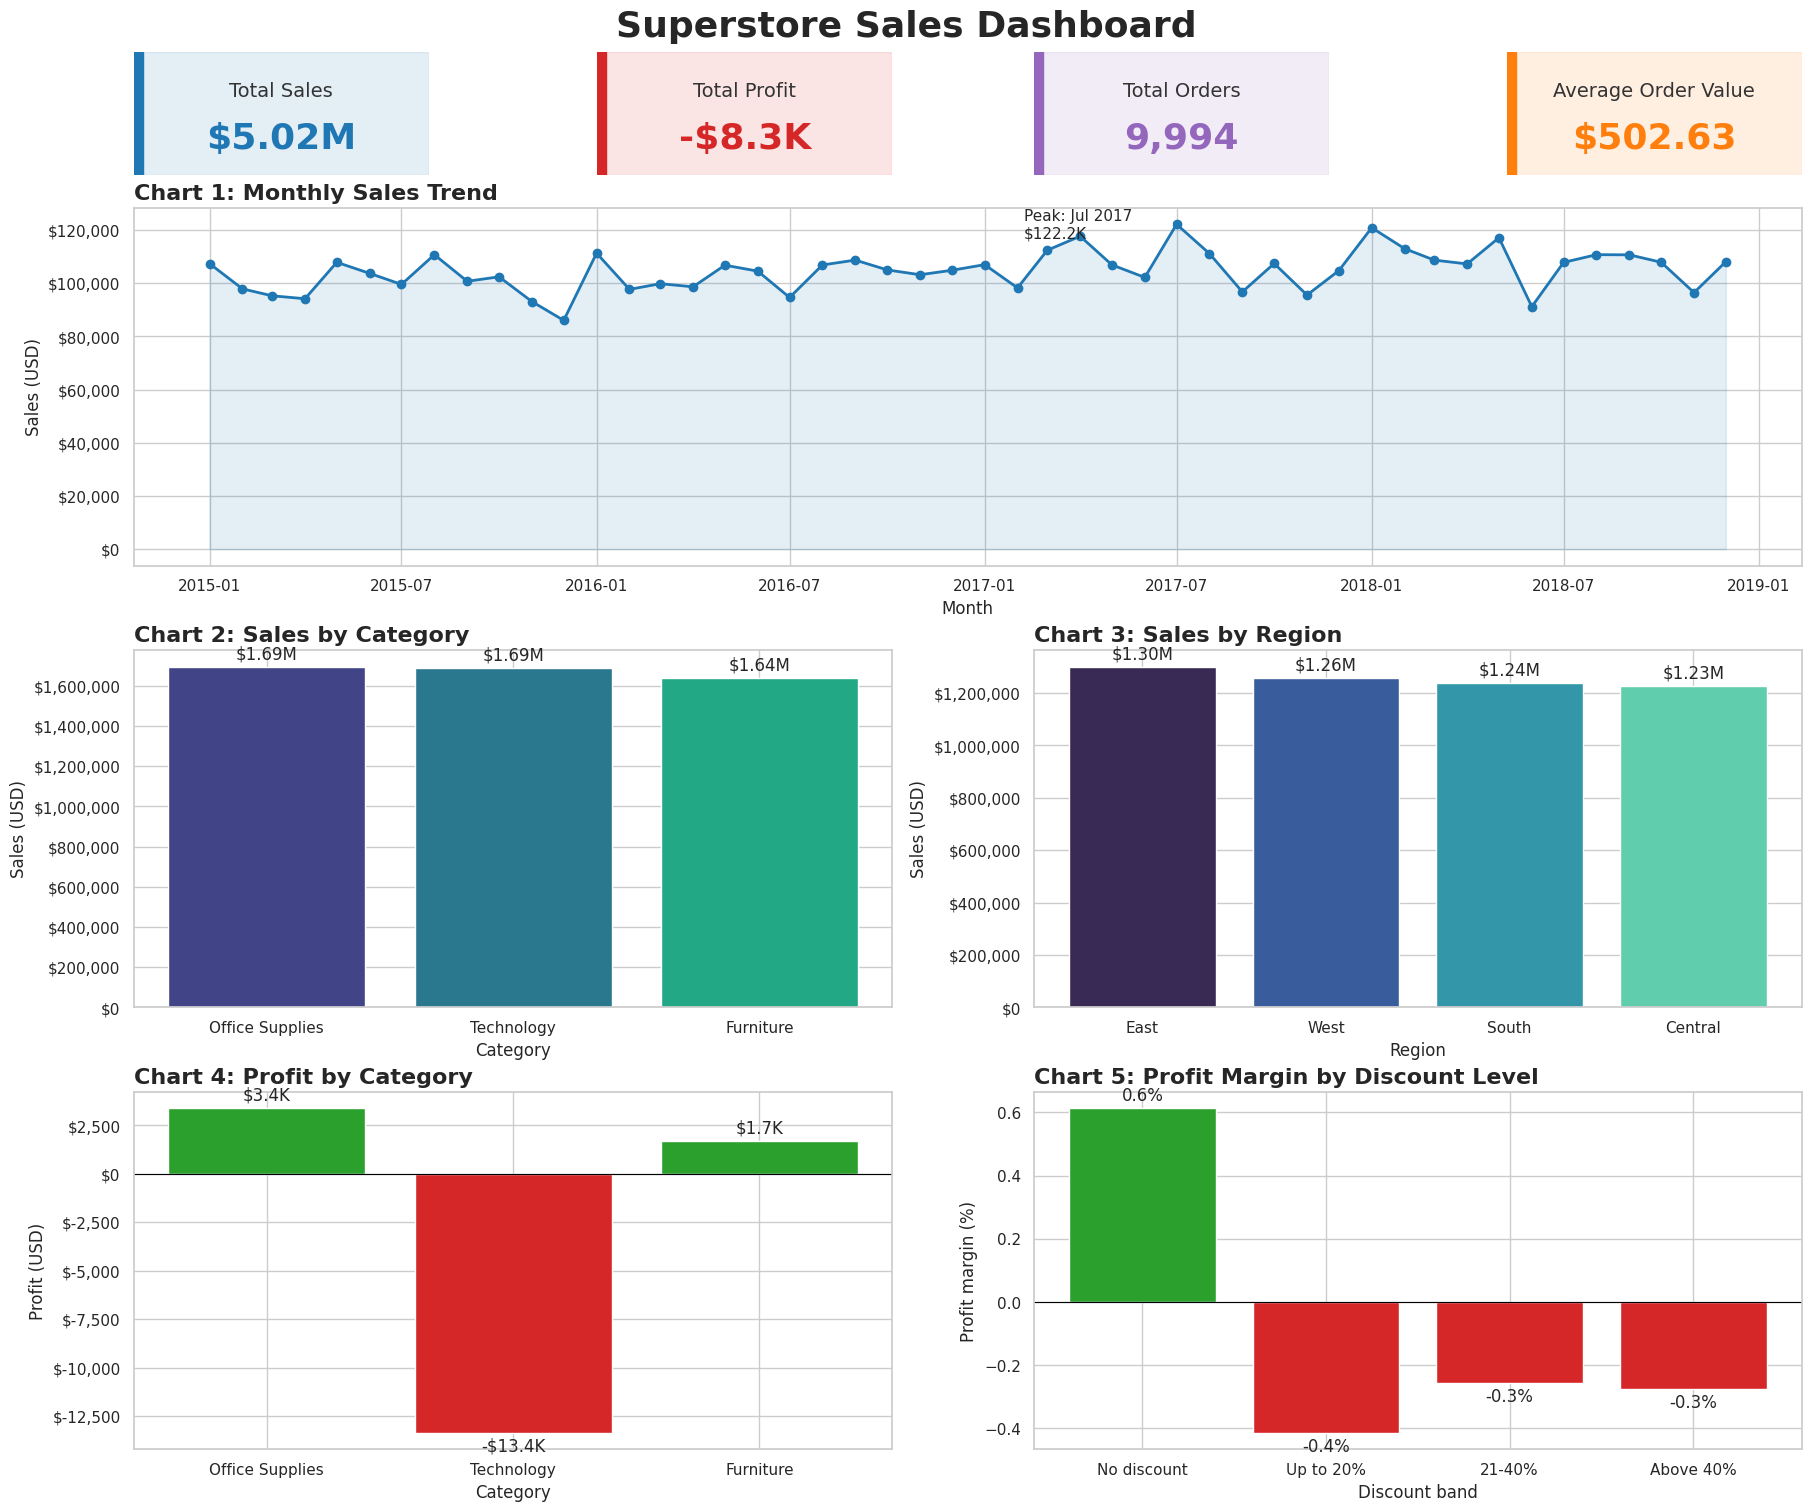

In [21]:
money = mtick.FuncFormatter(lambda x, _: f"${x:,.0f}")
def short_money(v):
    a = abs(v)
    s = f"{a/1e6:.2f}M" if a >= 1e6 else f"{a/1e3:.1f}K" if a >= 1e3 else f"{a:,.0f}"
    return ("-$" if v < 0 else "$") + s

palette = sns.color_palette("viridis", 4)
fig = plt.figure(figsize=(18, 15), constrained_layout=True)
gs = GridSpec(4, 4, figure=fig, height_ratios=[0.45, 1.3, 1.3, 1.3])
fig.suptitle("Superstore Sales Dashboard", fontsize=26, fontweight="bold")

# --- KPI cards ---
cards = [("Total Sales", short_money(total_sales), "#1f77b4"),
         ("Total Profit", short_money(total_profit), "#2ca02c" if total_profit >= 0 else "#d62728"),
         ("Total Orders", f"{total_orders:,}", "#9467bd"),
         ("Average Order Value", f"${aov:,.2f}", "#ff7f0e")]
for i, (title, value, color) in enumerate(cards):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color=color, alpha=0.12))
    ax.add_patch(plt.Rectangle((0, 0), 0.03, 1, transform=ax.transAxes, color=color))
    ax.text(0.5, 0.68, title, ha="center", va="center", fontsize=14, color="#333", transform=ax.transAxes)
    ax.text(0.5, 0.30, value, ha="center", va="center", fontsize=26, fontweight="bold", color=color, transform=ax.transAxes)

# --- Chart 1: monthly sales trend ---
ax1 = fig.add_subplot(gs[1, :])
ax1.plot(monthly.index, monthly["Sales"], marker="o", color="#1f77b4", linewidth=2)
ax1.fill_between(monthly.index, monthly["Sales"], alpha=0.12, color="#1f77b4")
peak = monthly["Sales"].idxmax()
ax1.annotate(f"Peak: {peak:%b %Y}\n{short_money(monthly['Sales'].max())}",
             (peak, monthly["Sales"].max()), xytext=(-110, -10), textcoords="offset points",
             arrowprops=dict(arrowstyle="->"), fontsize=11)
ax1.set_title("Chart 1: Monthly Sales Trend", fontsize=16, fontweight="bold", loc="left")
ax1.set_xlabel("Month"); ax1.set_ylabel("Sales (USD)"); ax1.yaxis.set_major_formatter(money)

# --- Chart 2: sales by category ---
ax2 = fig.add_subplot(gs[2, :2])
cat_sorted = by_category.sort_values("Sales", ascending=False)
bars = ax2.bar(cat_sorted.index, cat_sorted["Sales"], color=palette[:len(cat_sorted)])
ax2.bar_label(bars, labels=[short_money(v) for v in cat_sorted["Sales"]], padding=3)
ax2.set_title("Chart 2: Sales by Category", fontsize=16, fontweight="bold", loc="left")
ax2.set_xlabel("Category"); ax2.set_ylabel("Sales (USD)"); ax2.yaxis.set_major_formatter(money)

# --- Chart 3: sales by region ---
ax3 = fig.add_subplot(gs[2, 2:])
reg_sorted = by_region.sort_values("Sales", ascending=False)
bars = ax3.bar(reg_sorted.index, reg_sorted["Sales"], color=sns.color_palette("mako", len(reg_sorted)))
ax3.bar_label(bars, labels=[short_money(v) for v in reg_sorted["Sales"]], padding=3)
ax3.set_title("Chart 3: Sales by Region", fontsize=16, fontweight="bold", loc="left")
ax3.set_xlabel("Region"); ax3.set_ylabel("Sales (USD)"); ax3.yaxis.set_major_formatter(money)

# --- Chart 4: profit by category ---
ax4 = fig.add_subplot(gs[3, :2])
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in cat_sorted["Profit"]]
bars = ax4.bar(cat_sorted.index, cat_sorted["Profit"], color=colors)
ax4.bar_label(bars, labels=[short_money(v) for v in cat_sorted["Profit"]], padding=3)
ax4.axhline(0, color="black", linewidth=0.8)
ax4.set_title("Chart 4: Profit by Category", fontsize=16, fontweight="bold", loc="left")
ax4.set_xlabel("Category"); ax4.set_ylabel("Profit (USD)"); ax4.yaxis.set_major_formatter(money)

# --- Chart 5: profit margin by discount band ---
ax5 = fig.add_subplot(gs[3, 2:])
dm = by_discount["Profit Margin %"]
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in dm.fillna(0)]
bars = ax5.bar(dm.index.astype(str), dm.fillna(0), color=colors)
ax5.bar_label(bars, labels=[f"{v:.1f}%" for v in dm.fillna(0)], padding=3)
ax5.axhline(0, color="black", linewidth=0.8)
ax5.set_title("Chart 5: Profit Margin by Discount Level", fontsize=16, fontweight="bold", loc="left")
ax5.set_xlabel("Discount band"); ax5.set_ylabel("Profit margin (%)")

fig.savefig("superstore_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 6. Explain the findings


In [22]:
top_cat      = by_category.index[0]
low_cat      = by_category.index[-1]
worst_margin_cat = by_category["Profit Margin %"].idxmin()
best_margin_cat  = by_category["Profit Margin %"].idxmax()
top_region   = by_region.index[0]
low_region   = by_region.index[-1]
worst_margin_region = by_region["Profit Margin %"].idxmin()
best_month   = monthly["Sales"].idxmax()
worst_month  = monthly["Sales"].idxmin()
best_cal_month = seasonal.idxmax()
worst_cal_month = seasonal.idxmin()
loss_share   = (df["Profit"] < 0).mean()
loss_total   = df.loc[df["Profit"] < 0, "Profit"].sum()
neg_cats     = by_category.index[by_category["Profit"] < 0].tolist()
neg_regions  = by_region.index[by_region["Profit"] < 0].tolist()
worst_sub    = by_subcat.index[0]
heavy        = by_discount.iloc[-1]
first_year, last_year = int(yearly.index.min()), int(yearly.index.max())
yoy = (yearly["Sales"].iloc[-1] / yearly["Sales"].iloc[0] - 1) * 100 if len(yearly) > 1 else float("nan")

findings = [
    f"Total sales were ${total_sales:,.2f} and total profit was ${total_profit:,.2f} (margin {profit_margin:.2%}) across {total_orders:,} orders ({total_lines:,} line items).",
    f"{top_cat} generated the most sales (${by_category.loc[top_cat,'Sales']:,.2f}, {by_category.loc[top_cat,'Share of Sales %']:.1f}% of total); {low_cat} generated the least.",
    f"{best_margin_cat} has the best profit margin ({by_category.loc[best_margin_cat,'Profit Margin %']:.2f}%) and {worst_margin_cat} the weakest ({by_category.loc[worst_margin_cat,'Profit Margin %']:.2f}%).",
    f"{top_region} is the top region by sales (${by_region.loc[top_region,'Sales']:,.2f}); {low_region} is the lowest. {worst_margin_region} has the lowest margin ({by_region.loc[worst_margin_region,'Profit Margin %']:.2f}%).",
    f"The highest monthly sales occurred in {best_month:%B %Y} (${monthly.loc[best_month,'Sales']:,.2f}) and the lowest in {worst_month:%B %Y} (${monthly.loc[worst_month,'Sales']:,.2f}).",
    f"Across all years, {best_cal_month} is the strongest calendar month and {worst_cal_month} the weakest.",
    f"{loss_share:.1%} of line items lost money, totalling ${loss_total:,.2f} in losses.",
    f"Correlation between discount and profit is {discount_corr:.2f}; lines discounted above 40% had a margin of {heavy['Profit Margin %']:.1f}%." if pd.notna(heavy["Profit Margin %"]) else f"Correlation between discount and profit is {discount_corr:.2f}.",
]
for f in findings:
    print("-", f)

- Total sales were $5,023,276.42 and total profit was $-8,295.89 (margin -0.17%) across 9,994 orders (9,994 line items).
- Office Supplies generated the most sales ($1,694,191.27, 33.7% of total); Furniture generated the least.
- Office Supplies has the best profit margin (0.20%) and Technology the weakest (-0.79%).
- East is the top region by sales ($1,299,695.57); Central is the lowest. South has the lowest margin (-0.48%).
- The highest monthly sales occurred in July 2017 ($122,152.14) and the lowest in December 2015 ($86,041.54).
- Across all years, Jan is the strongest calendar month and Nov the weakest.
- 50.7% of line items lost money, totalling $-471,995.08 in losses.
- Correlation between discount and profit is -0.00; lines discounted above 40% had a margin of -0.3%.
